# Vocalisation of the corpora

This notebook measures how vocalised the corpora are, and sets a threshold
above which a verse is considered vocalised. It is applied to Ashaar and then to
MetRec. The *ṭawīl* is looked at in particular, because the thesis focuses on
it.

**Observed** marks what the data show, **Interpretation** our own reading.

## The challenge: measuring vocalisation

Arabic is usually written without short vowels. The verses must be vocalised
for the *taqṭīʿ* (scansion) to be done effectively. The corpora mix fully
vocalised verses, partly vocalised verses and verses without any vowel. We therefore need a simple measure, computed on each
verse, and a threshold to keep only the verses that are vocalised enough.

We compare two measures:

- **Raw ratio**: number of diacritics divided by number of Arabic letters. The
  diacritics are the characters U+064B to U+0652: *tanwīn*, *fatḥa*, *ḍamma*,
  *kasra*, *šadda* and *sukūn*. The *tatwīl* (ـ), a stretching character, is not
  counted as a letter.
- **Adjusted ratio**: the same, but some letters are removed from the
  denominator because they carry no mark even in a fully vocalised text: ا, آ,
  ى, and و / ي without any mark. Treating every unmarked و / ي as a long vowel is
  an approximation.

Without this adjustment, a fully vocalised verse never comes close to 1,
because its long-vowel letters lower the ratio.

In [1]:
import pathlib
import re

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["font.family"] = "DejaVu Sans"
RAW = pathlib.Path(".")   # data/1_raw/, which holds one folder per corpus

DIACRITICS = re.compile("[\u064B-\u0652]")                 # fatḥatān ... sukūn
LETTERS = re.compile("[\u0621-\u063A\u0641-\u064A]")     # hamza ... yāʾ, tatwīl excluded
# Letters that carry no mark even in a fully vocalised text: ا, آ, ى,
# and و / ي without any mark (read as long vowels).
NO_MARK = re.compile("[\u0627\u0622\u0649]|[\u0648\u064A](?![\u064B-\u0652])")

def ratios(strings):
    """Raw and adjusted ratio of a list of strings."""
    text = " ".join(strings)
    letters = len(LETTERS.findall(text))
    marks = len(DIACRITICS.findall(text))
    adjusted_letters = letters - len(NO_MARK.findall(text))
    return (marks / letters if letters else None,
            marks / adjusted_letters if adjusted_letters > 0 else None)

BINS = [-0.001, 0, 0.2, 0.4, 0.6, 0.7, 0.8, 1.0, float("inf")]
NAMES = ["0", "0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.7", "0.7–0.8", "0.8–1.0", "> 1.0"]

def ratio_table(frame, groups):
    """Counts per ratio level, raw and adjusted, for each group (name -> boolean mask)."""
    def counts(series):
        return pd.cut(series, BINS, labels=NAMES).value_counts().reindex(NAMES)
    return pd.DataFrame({(name, kind): counts(frame.loc[mask, kind])
                         for name, mask in groups.items() for kind in ("raw", "adjusted")})

def plot_ratio_table(table, unit):
    groups = table.columns.get_level_values(0).unique()
    fig, axes = plt.subplots(1, len(groups), figsize=(11, 4), sharey=True)
    for ax, group in zip(axes, groups):
        table[group].plot.barh(ax=ax)
        ax.set_title(group)
        ax.set_xlabel(unit)
    axes[0].set_ylabel("ratio")
    fig.tight_layout()
    plt.show()

LEVELS = [(0, 0.2, 1), (0.2, 0.4, 1), (0.4, 0.7, 2), (0.7, None, 4)]

def print_levels(verses, who):
    """Print random verses by level of the adjusted ratio (fixed seed)."""
    number = 0
    for low, high, size in LEVELS:
        if high is None:
            level, name = verses[verses["adjusted"] > low], f"> {low}"
        else:
            level = verses[(verses["adjusted"] > low) & (verses["adjusted"] <= high)]
            name = f"{low}–{high}"
        print(f"=== adjusted {name}")
        for _, row in level.sample(size, random_state=0).iterrows():
            number += 1
            print(f"{number}. {who(row)}raw {row['raw']:.2f} | adjusted {row['adjusted']:.2f}")
            print(f"   {row['sadr']}  #  {row['ajuz']}")
        print()

def threshold_table(groups):
    """Verses at or below 0.7 and above 0.7 (adjusted), for each group of verses."""
    rows = {}
    for name, frame in groups.items():
        above = (frame["adjusted"] > 0.7).sum()
        rows[name] = {"adjusted ≤ 0.7": len(frame) - above, "adjusted > 0.7": above,
                      "total": len(frame)}
    table = pd.DataFrame(rows).T
    display(table)
    fig, axes = plt.subplots(1, len(rows), figsize=(10, 2.5))
    for ax, (name, row) in zip(axes, table.iterrows()):
        ax.barh(["≤ 0.7", "> 0.7"], row[["adjusted ≤ 0.7", "adjusted > 0.7"]].values)
        ax.set_title(name)
        ax.set_xlabel("verses")
    fig.tight_layout()
    plt.show()

## Case study: Ashaar

Unit of the first table: **poems**.

all poems          ṭawīl poems         
              raw adjusted         raw adjusted
0           23908    23908        2070     2070
0–0.2      115142    95711       12476    10727
0.2–0.4     47103    46746        6156     5192
0.4–0.6     51134    28912       11260     4144
0.6–0.7      8977    27386        1655     6092
0.7–0.8      5466    18493         620     4646
0.8–1.0      2869    10669         345     1403
> 1.0          17     2791           0      308

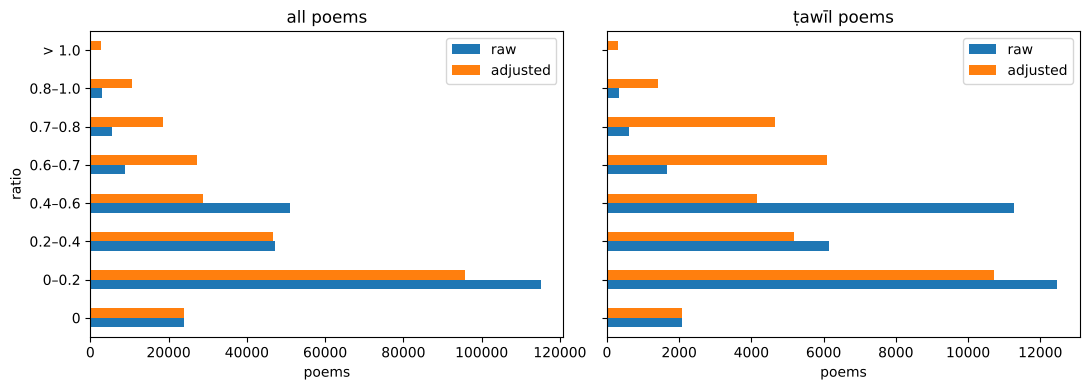

In [2]:
df = pd.concat([pd.read_parquet(path) for path in sorted((RAW / "ashaar").glob("*.parquet"))],
               ignore_index=True)
TAWIL = ["الطويل", "بحر الطويل", "بحر مجزوء الطويل", "بحر مشطور الطويل"]
df["tawil"] = df["poem meter"].isin(TAWIL)
df[["raw", "adjusted"]] = df["poem verses"].map(ratios).tolist()

table = ratio_table(df, {"all poems": df.index == df.index, "ṭawīl poems": df["tawil"]})
display(table)
plot_ratio_table(table, "poems")

**Observed.** With the raw ratio, only 8,352 poems (3%) are above 0.7, and
965 *ṭawīl* poems (3%). With the adjusted ratio, 31,953 poems (13%) and 6,357
*ṭawīl* poems (18%) are above 0.7. The adjusted *ṭawīl* distribution has two
peaks, one below 0.2 and one between 0.6 and 0.8.

### Random *ṭawīl* verses by level of the adjusted ratio

From here on, the unit is the **verse**: a pair of consecutive strings
(*ṣadr*, *ʿaǧuz*) in the poems with an even number of strings. Both ratios are
computed on each verse.

In [3]:
# A verse is a pair of consecutive strings (ṣadr, ʿaǧuz) in the poems with an
# even number of strings.
even = df[(df["poem verses"].map(len) % 2 == 0) & (df["poem verses"].map(len) > 0)]
verses = even[["poet name", "poem meter", "tawil", "poem verses"]].copy()
verses["pair"] = verses["poem verses"].map(lambda v: [(v[i], v[i + 1]) for i in range(0, len(v), 2)])
verses = verses.drop(columns="poem verses").explode("pair", ignore_index=True)
verses["sadr"] = verses["pair"].str[0]
verses["ajuz"] = verses["pair"].str[1]
verses[["raw", "adjusted"]] = verses["pair"].map(ratios).tolist()

print_levels(verses[verses["tawil"]], lambda row: f"({row['poet name']}) ")

=== adjusted 0–0.2
1. (محمد بيرم الثاني) raw 0.03 | adjusted 0.03
   وقـــد ظـــهــرت آثــاره بــحــديــثــهــا  #  حــداة الورى تــحــدو بــه كــلّ مـوسـم

=== adjusted 0.2–0.4
2. (الطغرائي) raw 0.30 | adjusted 0.39
   ولي قِبَلَ الأيامِ منذ صِحِبْتُها  #  مواعيدُ قد أعلقنَها شرَكَ المطلِ

=== adjusted 0.4–0.7
3. (ابن الرومي) raw 0.33 | adjusted 0.43
   تجنَّتْ فقال الكاشحونَ تجنَّتِ  #  وضنَّت فقال الناس ويحك ضَنَّتِ
4. (ابو نواس) raw 0.51 | adjusted 0.66
   تَقولُ لِيَ الرُكبانُ ما لَكَ راجِلاً  #  وَكُنتُ رَكوباً عَصرَ نَحنُ رِجالُ

=== adjusted > 0.7
5. (خليل مطران) raw 0.88 | adjusted 1.00
   وَلَكِــنْ إِذَا مَـلَّكْـتَ قَـلْبـكَ فَـاحْـتَـفِـظْ  #  بِـرَسْـمِـي وَحَـسْـبِـي فِـيـهِ أَصْـغَـرُ مَوْضِعِ
6. (سليمان البستاني) raw 0.63 | adjusted 0.77
   وزَفــرَةُ مَــقــتُــولٍ ونَــعــرَةُ قــاتِــلٍ  #  بِــسَــيــلِ دِمــاءٍ بــالأَسِــنَّةــِ مُهــرَقِ
7. (أبو فراس الحمداني) raw 0.62 | adjusted 0.74
   أُقيمُ بِهِ أَصلُ الفَخارِ وَفَرعُهُ  #  وَشُدَّ بِهِ رُكنُ العُلا وَدَعائِ

**Interpretation** (our reading). Verses 1 and 2 have almost no vowels or only
a few. Verse 3 (0.43) has vowels on some words only. Verse 4 (0.66) is already
complete except for *sukūn*. Verses 5–8 (above 0.7) are well vocalised.

The raw ratio underestimates vocalisation: a well-vocalised verse such as 7
only reaches 0.62. A threshold of 0.7 on the adjusted ratio is safe but
conservative: some good verses, like 4, fall just below it.

### Verses above 0.7 (adjusted)

,adjusted ≤ 0.7,adjusted > 0.7,total
all verses,2856617,438644,3295261
ṭawīl verses,346471,75334,421805


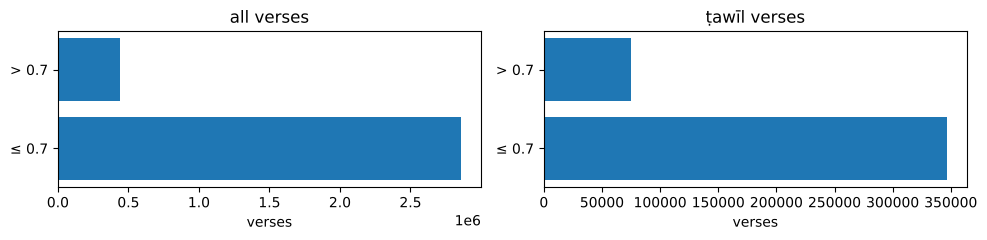

In [4]:
threshold_table({"all verses": verses, "ṭawīl verses": verses[verses["tawil"]]})

**Observed.** 75,334 *ṭawīl* verses (18%) and 438,644 verses overall (13%) have
an adjusted ratio above 0.7.

## Case study: MetRec

MetRec is already split into verses (`train.txt` and `test.txt` together).
Unit: **verses**.

all verses          ṭawīl verses         
               raw adjusted          raw adjusted
0             5763     5763           23       23
0–0.2         9593     7328           76       73
0.2–0.4       9367     6476          273       22
0.4–0.6      20911     8982         3165      612
0.6–0.7       5710    11221         1049     1671
0.7–0.8       2591     8701          351     1533
0.8–1.0       1485     5875           63     1041
> 1.0           20     1094            0       25

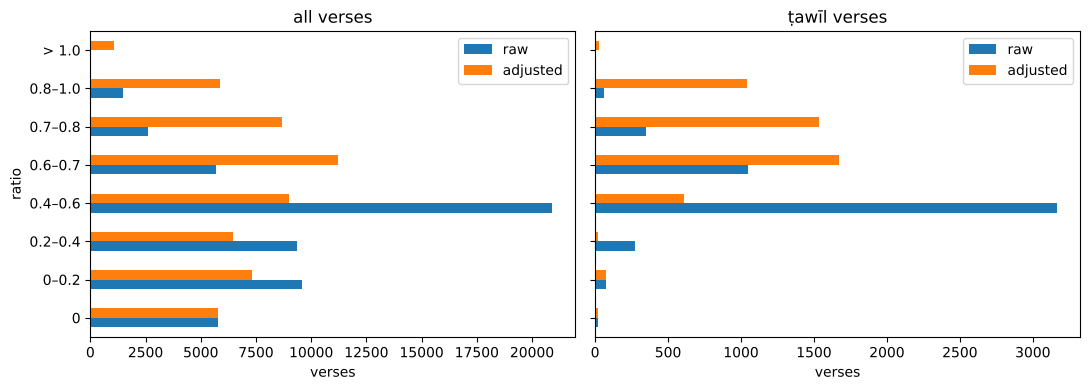

In [5]:
folder = RAW / "metrec"
labels = (folder / "labels.txt").read_text(encoding="utf-8").split()
rows = []
for split in ["train", "test"]:
    for line in (folder / f"{split}.txt").read_text(encoding="utf-8").splitlines():
        number, verse = line.split(" ", 1)
        sadr, ajuz = verse.split(" # ", 1)
        rows.append({"split": split, "meter": labels[int(number)], "sadr": sadr, "ajuz": ajuz})
metrec = pd.DataFrame(rows)
metrec["tawil"] = metrec["meter"] == "taweel"
metrec[["raw", "adjusted"]] = [ratios([s, a]) for s, a in zip(metrec["sadr"], metrec["ajuz"])]

table = ratio_table(metrec, {"all verses": metrec.index == metrec.index,
                             "ṭawīl verses": metrec["tawil"]})
display(table)
plot_ratio_table(table, "verses")

**Observed.** MetRec is more vocalised than Ashaar, especially for the
*ṭawīl*. With the raw ratio, only 414 of its 5,000 *ṭawīl* verses (8%) are above
0.7, most of them (3,165) lying between 0.4 and 0.6. With the adjusted ratio,
2,599 (52%) are above 0.7.

### Random *ṭawīl* verses by level of the adjusted ratio

In [6]:
print_levels(metrec[metrec["tawil"]], lambda row: f"({row['split']}) ")

=== adjusted 0–0.2
1. (train) raw 0.07 | adjusted 0.10
   تعالي إلى صدرٍ رحيبٍ وساعدٍ  #  حبيب وركن في الهوى غير منهد

=== adjusted 0.2–0.4
2. (test) raw 0.29 | adjusted 0.39
   جَريئاً حريا بِالْخِلافَة مُجْمعاً  #  عليْهِ فبُشرى الدّين بالأجرأ الأحرَى

=== adjusted 0.4–0.7
3. (train) raw 0.52 | adjusted 0.70
   وَأَنتِ الَّتي كَلَّفتِني دَلَجَ السُرى  #  وَجونُ القَطا بِالجِلهَتَينِ جُثومُ
4. (train) raw 0.55 | adjusted 0.70
   فَوَاللَهِ ما أَبكي عَلى يَومِ ميتَتي  #  وَلَكِنَّني مِن وَشكِ بَينِكِ أَجزَعُ

=== adjusted > 0.7
5. (train) raw 0.65 | adjusted 0.79
   وكَمْ سُؤدَدٍ فينا تَرَدَّدَ مَحضُه  #  ومَجْدٍ أَبَى إبلاءَ جِدّتِهِ الدَّهْرُ
6. (test) raw 0.62 | adjusted 0.77
   دَعوني فَما عَن رَأيِكُم كانَ حُبُّها  #  وَلَكِنَّهُ حَظٌّ لَها وَقَسيمُ
7. (test) raw 0.62 | adjusted 0.80
   وَلا رَيبَةٌ إِلّا الحَديثُ كَأَنَّهُ  #  جُمانٌ وَهى أَو لُؤلُؤٌ مُتَناثِرُ
8. (train) raw 0.64 | adjusted 0.84
   سَمَا بِأَبِيهِ حِينَ سَمَّوْهُ باسْمِهِ  #  فاللَّهِ مِنْ سامِي المَراتِبِ سامِق

**Interpretation** (our reading). Verse 1 has almost no vowels, verse 2 has
vowels on some words. Verses 3 and 4 (exactly 0.70) are complete except for
*sukūn*, and verses 5–8 are well vocalised. As for Ashaar, the threshold of 0.7
leaves out some good verses.

### Verses above 0.7 (adjusted)

,adjusted ≤ 0.7,adjusted > 0.7,total
all verses,39770,15670,55440
ṭawīl verses,2401,2599,5000


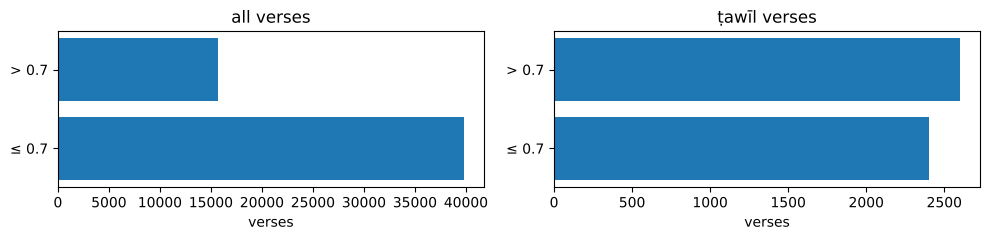

In [7]:
threshold_table({"all verses": metrec, "ṭawīl verses": metrec[metrec["tawil"]]})

**Observed.** 2,599 *ṭawīl* verses (52%) and 15,670 verses overall (28%) have an
adjusted ratio above 0.7.

## Conclusion

We keep the verses with an **adjusted ratio above 0.7**. This gives 75,334
*ṭawīl* verses in Ashaar and 2,599 in MetRec, with good vocalisation. The
threshold is conservative: some well-vocalised verses fall just below it. The
ratio counts the marks, not whether they are correct: typos and wrong case
endings also exist.

## Overlap between MetRec and Ashaar

According to its authors, MetRec was collected from Aldiwan, which is also one
of the sources of Ashaar. Method:

1. **Put the verses in the same form.** The two corpora do not store verses
   the same way:
   - in MetRec, each line is already a full verse:
     `أَلا لَيتَ شِعري هَل أَبيتَنَّ لَيلَةً # أُلاطِمُ أَعناقَ الرُبى بِالمَناسِمِ`;
   - in Ashaar, a poem is a list of hemistichs:
     `["ṣadr 1", "ʿaǧuz 1", "ṣadr 2", "ʿaǧuz 2", ...]`. The verses are rebuilt
     by joining the strings two by two (1 with 2, 3 with 4, ...), which gives
     `ṣadr 1 # ʿaǧuz 1`, `ṣadr 2 # ʿaǧuz 2`, ... Only poems with an even number
     of strings are used, otherwise the pairs would be shifted.
2. **Normalise both sides in the same way**: remove diacritics and *tatwīl*,
   collapse spaces. The same verse can be vocalised differently from one
   source to another.
3. Count the MetRec verses found identically in Ashaar, separately for `train`
   and `test`, and check whether both corpora give the same *baḥr* (variants
   such as مجزوء are compared on the *baḥr* name only).

Unit: **MetRec verses**.

In [8]:
# Same normalisation on both sides: no diacritics, no tatwīl, single spaces.
STRIP = re.compile("[\u064B-\u0652\u0640]")

def key(sadr, ajuz):
    return " ".join(STRIP.sub("", sadr).split()) + " # " + " ".join(STRIP.sub("", ajuz).split())

# Baḥr named by an Ashaar label (e.g. بحر مجزوء الطويل -> طويل) and by a MetRec label.
BUHUR = ["طويل", "مديد", "بسيط", "وافر", "كامل", "هزج", "رجز", "رمل", "سريع",
         "منسرح", "خفيف", "مضارع", "مقتضب", "مجتث", "متقارب", "متدارك"]
METREC_BAHR = {"saree": "سريع", "kamel": "كامل", "mutakareb": "متقارب", "mutadarak": "متدارك",
               "munsareh": "منسرح", "madeed": "مديد", "mujtath": "مجتث", "ramal": "رمل",
               "baseet": "بسيط", "khafeef": "خفيف", "taweel": "طويل", "wafer": "وافر",
               "hazaj": "هزج", "rajaz": "رجز"}

def ashaar_bahr(label):
    if not isinstance(label, str):
        return None
    for word in label.removeprefix("بحر ").split():
        if word.removeprefix("ال") in BUHUR:
            return word.removeprefix("ال")
    return None

verses["key"] = [key(s, a) for s, a in zip(verses["sadr"], verses["ajuz"])]
verses["bahr"] = verses["poem meter"].map(ashaar_bahr)
ashaar_meters = verses.groupby("key")["bahr"].agg(lambda b: set(b.dropna()))

metrec["key"] = [key(s, a) for s, a in zip(metrec["sadr"], metrec["ajuz"])]
metrec["in ashaar"] = metrec["key"].isin(ashaar_meters.index)
metrec["same meter"] = [found and METREC_BAHR[m] in ashaar_meters[k]
                        for found, m, k in zip(metrec["in ashaar"], metrec["meter"], metrec["key"])]

def overlap(frame):
    found = frame["in ashaar"].sum()
    return {"MetRec verses": len(frame), "found in Ashaar": found,
            "% found": round(100 * found / len(frame), 1),
            "found, same meter": frame["same meter"].sum()}

pd.DataFrame.from_dict(orient="index", data={
    "train": overlap(metrec[metrec["split"] == "train"]),
    "test": overlap(metrec[metrec["split"] == "test"]),
    "all": overlap(metrec),
    "ṭawīl (all)": overlap(metrec[metrec["tawil"]]),
})

,MetRec verses,found in Ashaar,% found,"found, same meter"
train,47124,45060,95.6,44458
test,8316,7963,95.8,7880
all,55440,53023,95.6,52338
ṭawīl (all),5000,5000,100.0,5000


**Observed.** 53,023 of the 55,440 MetRec verses (95.6%) are found identically
in Ashaar, in the same proportion for `train` and `test`. All 5,000 MetRec
*ṭawīl* verses are found. For 52,338 of the verses found (98.7%), Ashaar gives
the same *baḥr*.

**Interpretation.** MetRec is almost entirely contained in Ashaar. The two
corpora cannot be added together without removing these duplicates, and a
model trained on Ashaar cannot be evaluated on MetRec's `test` without
leakage. The 4.4% not found probably differ by small text variants, or come
from poems with an odd number of strings.

## Decision: Ashaar only

We keep **Ashaar only** and do not use MetRec:
- for the *ṭawīl*, MetRec adds no new verse: all its 5,000 verses are in Ashaar;
- Ashaar has far more well-vocalised *ṭawīl* verses (75,334 against 2,599 above
  0.7);
- Ashaar gives the poet and the era, which MetRec does not.